# Reese's Cups: Peanut Butter Volume Investigation

This document provides work to determine an approximation of the peanut butter ratio by volume for Reese's Cups of different sizes.  Specifically, the ratio is determined for the common miniature size obtained at Halloween and the standard full-size cups.  An image showing the final results is shown immediately below with supporting work to follow.

In [12]:
from IPython.display import Image
import math

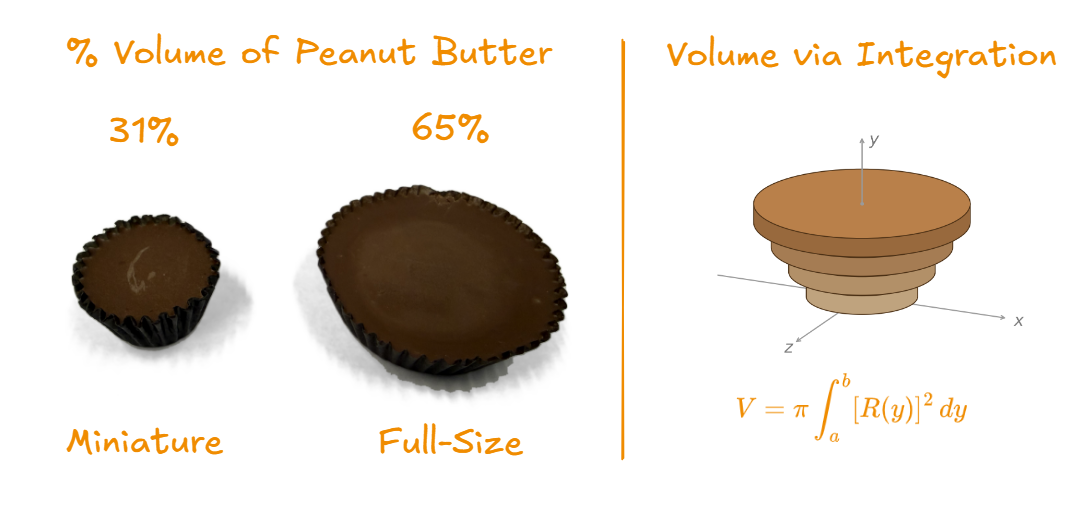

In [4]:
Image(filename='ReeseCups_Volume.png') 

## Method

Computing the percentage volume of peanut butter can be determined by computing first the volume of the cup and then the peanut butter filled middle.  A technique involving integration can be used to estimate these volumes with only a few dimensions measured from the cups.  This technique is shown in the above image where the cup can be approximated with a series of circular discs.  Computing the volume of each disc and summing them together provides the estimate of the volume of interest.  Then it is just a matter of continually decreasing the heights of the discs to improve the accuracy.  This is essentially what is done when performing the integral shown above.  

The integral also requires the determination of the radius as a function of the position along the y-axis.  This can be determined by examining a cross section of the cup as shown below.  This image showing only half the overall cross section whereas the entire shape can be approximated with a revolution around the y-axis.  By focusing on the points $(r_1, 0)$ and $(r_2, h)$ a linear function can be determined to describe the change in radius associated with the vertical position.  

$$R(y) = r_1 + \left( \frac{r_2 - r_1}{h} \right)y$$

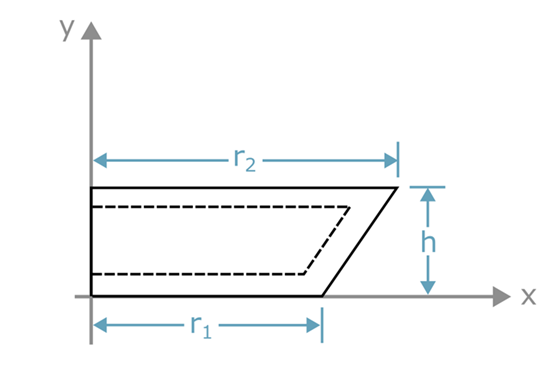

In [30]:
Image(filename='ReeseCups_CrossSection.png')

Solve the integral with the known radius function:

$$
\begin{aligned}
V &= \pi \int_0^h \left[ r_1 + \left( \frac{r_2 - r_1}{h} \right) y \right]^2 dy \\
  &= \pi \int_0^h r_1^2 + 2 r_1 y \left( \frac{r_2 - r_1}{h} \right) + \left( \frac{r_2 - r_1}{h} \right)^2 y^2 \, dy \\
  &= \pi \left[ r_1^2 y + r_1 y^2 \left( \frac{r_2 - r_1}{h} \right) + \left( \frac{r_2 - r_1}{h} \right)^2 \frac{y^3}{3} \right]_0^h \\
  &= \pi \left[ r_1^2 h + r_1 h^{\cancel{2}} \left( \frac{r_2 - r_1}{\cancel{h}} \right) + \left( \frac{r_2 - r_1}{h} \right)^2 \frac{h^3}{3} \right] \\
  &= \pi \left[ r_1^2 h + r_1 h (r_2 - r_1) + \left( \frac{r_2 - r_1}{h} \right)^2 \frac{h^3}{3} \right] \\
  &= \frac{\pi h}{3} \left[ 3r_1^2 + 3r_1 (r_2 - r_1) + (r_2 - r_1)^2 \right] \\
  &= \frac{\pi h}{3} \left( r_1^2 + r_1 r_2 + r_2^2 \right)
\end{aligned}
$$

## Computation

Now that the mathematics has been worked out, measurements neeed taken from the cups.  This corresponding dimesions (units: in) being shown in the table below.

| Cup | Volume | $h$ | $r_1$ | $r_2$ | 
| --- | --- | --- | --- | --- |
| Miniature | Total | 0.540 | 0.425 | 0.525 |
| Miniature | Peanut Butter | 0.300 | 0.305 | 0.405 |
| Full-Size | Total | 0.420 | 0.800 | 0.963 |
| Full-Size | Peanut Butter | 0.310 | 0.745 | 0.908 |

The following set of simplifying approximations were observed with the above dimensions.

1. Radii were approximated by measuring to the middle of the ridges.
2. The top thickness of the chocolate was measured and then applied as a uniform wall thickness.
3. Radial positions of the peanut butter ($r_1$ and $r_2$) were estimated by subtracting wall thicknesses from the outer points. 

Below are methods to compute the volume and display results.

In [27]:
def calc_volume(h: float, r_1: float, r_2: float) -> float:
    return (math.pi*h/3)*(r_1**2 + r_1*r_2 + r_2**2)

def display_volumes(total_vol: float, pb_vol: float):
    print(f"Total Volume:\t\t{total_vol:.3f}in^3")
    print(f"Peanut Butter Volume:\t{pb_vol:.3f}in^3")
    print(f"Ratio:\t\t\t{(pb_vol/total_vol)*100:.1f}%")

**Miniature Cups**

In [28]:
mini_total = calc_volume(0.540, 0.425, 0.525)
mini_pb = calc_volume(0.300, 0.305, 0.405)
display_volumes(mini_total, mini_pb)

Total Volume:		0.384in^3
Peanut Butter Volume:	0.120in^3
Ratio:			31.1%


**Full-Size Cups**

In [29]:
full_total = calc_volume(0.420, 0.800, 00.963)
full_pb = calc_volume(0.310, 0.745, 0.908)
display_volumes(full_total, full_pb)

Total Volume:		1.028in^3
Peanut Butter Volume:	0.667in^3
Ratio:			64.9%
